# Inspect the current repository IPI build: PDI, PLM and address map
Fresh Bootgen/readelf inspections run directly in this notebook. This is an offline file operation, not a hardware benchmark. Enable LIVE_RUNTIME to also program this same IPI image, collect new device timings and compare them with freshly measured Python references. No eFUSE/flash writes.

**Saved execution:** 2026-10-26T03:37:18.834029+00:00 (UTC). **fresh file inspection / Python; recorded board evidence**. No new board programming was performed by this notebook execution. Portable defaults below are restored to `LIVE=False`; saved outputs are retained. To repeat on your board, configure it and enable the live flag. Boot outputs show acceptance/recovery and host verification times, not on-chip boot latency.

In [1]:
from pathlib import Path
import sys, os, json, time, hashlib
import pandas as pd
ROOT = next((p for base in [Path.cwd(), *Path.cwd().parents]
             for p in (base, base/'scu35') if (p/'lab.py').is_file()), None)
assert ROOT is not None, 'Open the notebook from the repository checkout'
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT/'host'))
from lab import config, tool
from notebook import runtime, show_runtime, LiveRows, command, hardware, check_build
c = config()
OUT = Path(c['build_dir']).resolve()
print('Python:', sys.executable)
print('Build:', OUT)


Python: C:\aiup\pubvenv\Scripts\python.exe
Build: C:\aiup\s35p2


In [2]:
INSPECT_BUILD = False  # True after configuring/building your repository IPI image
if INSPECT_BUILD:
    pdi = check_build(c)
    command('inspect', '--pdi', pdi, '--elf', OUT/'plm.elf', c=c)
else:
    print('Current-build inspection skipped; showing source BD address map below.')
bd = json.loads((ROOT/'hw/sys.bd').read_text())
segments = bd['design']['addressing']['/mb']['address_spaces']['Data']['segments']
display(pd.DataFrame(segments).T[['address_block','offset','range']])


RUN: inspect --pdi C:\aiup\s35p2\demo.pdi --elf C:\aiup\s35p2\plm.elf


RUN D:\AMDDesignTools\2026.1\Vivado\bin\bootgen.bat


****** Bootgen v2026.1


  **** Build date : Jun  5 2026-13:21:08


    ** Copyright 1986-2022 Xilinx, Inc. All Rights Reserved.


...

  Segment Sections...


   00     .riscv.attributes


   01     .text.init .text .rodata .data .sdata .bss .sbss


   02     .stack


,address_block,offset,range
SEG_dlmb_bram_if_cntlr_Mem,/mb_local_memory/dlmb_bram_if_cntlr/SLMB/Mem,0x00000000,128K
SEG_pmc_ccu_apb_0,/pmc/CCU_APB/ccu_apb_0,0x04130000,64K
SEG_pmc_ccu_rd_stream_0,/pmc/CCU_RD_STREAM/ccu_rd_stream_0,0x04060000,64K
SEG_pmc_ccu_wr_stream_0,/pmc/CCU_WR_STREAM/ccu_wr_stream_0,0x04070000,64K
SEG_pmc_plm_config_0,/pmc/PLM_CONFIG/plm_config_0,0x04020000,64K
SEG_pmc_pmcl_aes_0,/pmc/PMC_AES/pmcl_aes_0,0x040F0000,64K
SEG_pmc_pmcl_dma_0,/pmc/PMCL_DMA/pmcl_dma_0,0x040E0000,64K
SEG_pmc_pmcl_efuse_0,/pmc/PMCL_EFUSE/pmcl_efuse_0,0x04160000,64K
SEG_pmc_pmcl_global_0,/pmc/PMCL_GLOBAL/pmcl_global_0,0x040A0000,128K
SEG_pmc_pmcl_ospi_0,/pmc/PMCL_OSPI/pmcl_ospi_0,0x04090000,64K


RECORDED HARDWARE + FRESH PYTHON; no board access


Measuring fresh Python references…


C:\aiup\s35p2\notebook_replay\f223ffb0\comparison.html


,run,algorithm,case,size_bytes,scu35_operation_mean_us,python_mean_us,SCU35 MB/s,Python MB/s,SCU35 operations/s,Python operations/s,results_match
0,1,SHA3-256,valid,16,23.7205,1.5479,0.674522,10.336585,42157.627369,646036.565670,True
1,1,SHA3-256,valid,64,23.7235,1.5138,2.697747,42.277712,42152.296246,660589.245607,True
2,1,SHA3-256,valid,256,23.9360,1.8216,10.695187,140.535793,41778.074866,548967.940272,True
3,1,SHA3-256,valid,1024,25.5150,3.5432,40.133255,289.004290,39192.631785,282230.751863,True
4,1,SHA3-256,valid,2048,27.6170,5.8385,74.157222,350.775028,36209.581055,171276.869059,True
5,1,SHAKE-256,valid,16,23.7460,1.5270,0.673798,10.478062,42112.355765,654878.847413,True
6,1,SHAKE-256,valid,64,23.7465,1.5283,2.695134,41.876595,42111.469059,654321.795459,True
7,1,SHAKE-256,valid,256,23.9545,1.7733,10.686927,144.363616,41745.809764,563920.374443,True
8,1,SHAKE-256,valid,1024,25.5325,3.4766,40.105748,294.540643,39165.769118,287637.346833,True
9,1,SHAKE-256,valid,2048,27.6390,6.2784,74.098195,326.197757,36180.759072,159276.248726,True


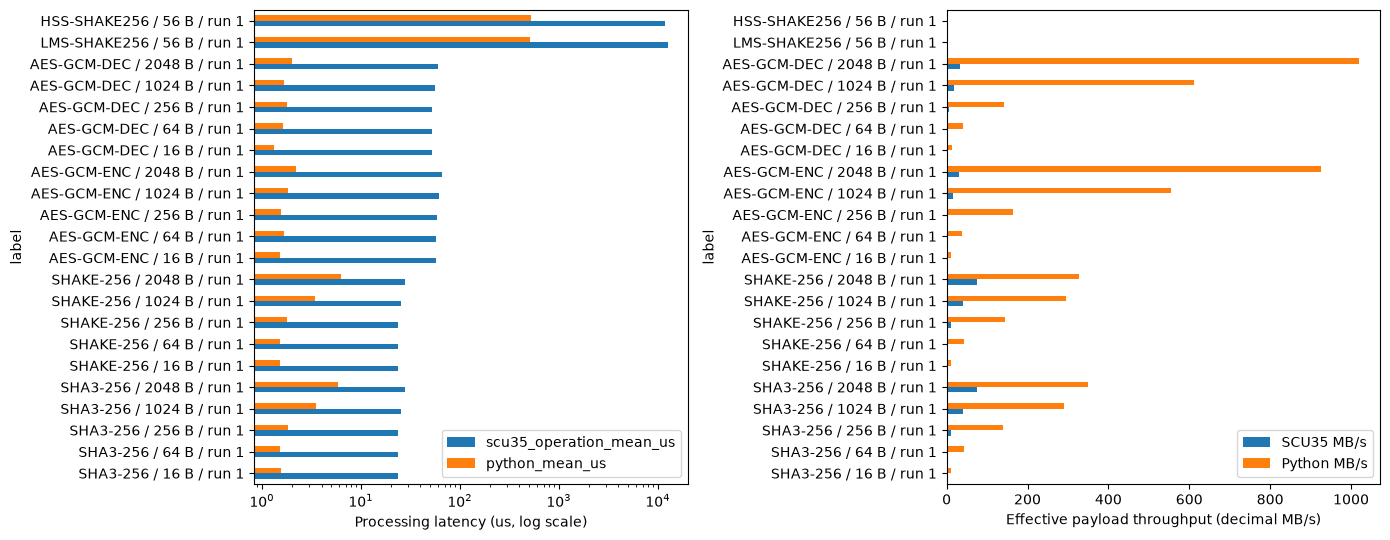

RECORDED HARDWARE + FRESH PYTHON: C:\aiup\s35p2\notebook_replay\f223ffb0\comparison.html
PUF and RNG lifecycle/generation results (different Python comparability):


,feature,hardware_us,status,python_equivalent,note,run
0,TRNG-HRNG-SETUP,36289.120,PASS,OS RNG setup is a different service,Initialization + self-tests + instantiation,1
1,TRNG-DRNG-SETUP,36782.940,PASS,OS RNG setup is a different service,Initialization + self-tests + instantiation,1
2,TRNG-PTRNG-SETUP,36259.490,PASS,OS RNG setup is a different service,Initialization + self-tests + instantiation,1
3,PUF-REGISTER,337.150,PASS,No physical equivalent,Volatile helper/key lifecycle; not export or s...,1
4,PUF-AES-ENC,40.700,PASS,No physical equivalent,Volatile helper/key lifecycle; not export or s...,1
5,PUF-KEY-CLEAR,2.940,PASS,No physical equivalent,Volatile helper/key lifecycle; not export or s...,1
6,PUF-REGENERATE,568.210,PASS,No physical equivalent,Volatile helper/key lifecycle; not export or s...,1
7,PUF-AES-DEC,34.720,PASS,No physical equivalent,Volatile helper/key lifecycle; not export or s...,1
8,TRNG-HRNG / 32 bytes,1623.515,20 successful calls; output length/nonzero/cha...,os.urandom(32): 0.264 us mean,Different randomness service; outputs must not...,1
9,TRNG-DRNG / 32 bytes,6.950,20 successful calls; output length/nonzero/cha...,os.urandom(32): 0.264 us mean,Different randomness service; outputs must not...,1


Device processing rates exclude programming/UART/JTAG. They are not physical bus bandwidth measurements.


In [3]:
LIVE_RUNTIME = False
reports = runtime(live=LIVE_RUNTIME, c=c, on_line=LiveRows() if LIVE_RUNTIME else None)
comparison = show_runtime(reports)
